# Exercise 1 (10 points)

In this exercise, we will practice refactoring concepts in analytics/data science tasks. Consider the following scenario. You're given a dataset of employee information, and you need to transform it to prepare for analysis. The initial function, `transform_employee_data`, does this by:

- Converting salary values to floats.
- Standardizing department names to lowercase.
- Adding a new column called `salary_level` based on salary thresholds.

However, the function is not well-structured or efficient. Your task is to refactor it to improve its design. Here’s the initial, unrefactored code:

```
import pandas as pd

def transform_employee_data(df):
    # Convert salary to float
    for i in range(len(df)):
        df.loc[i, 'salary'] = float(df.loc[i, 'salary'])

    # Standardize department names
    for i in range(len(df)):
        df.loc[i, 'department'] = df.loc[i, 'department'].lower()

    # Add salary level column
    for i in range(len(df)):
        salary = df.loc[i, 'salary']
        if salary < 50000:
            df.loc[i, 'salary_level'] = 'low'
        elif 50000 <= salary < 100000:
            df.loc[i, 'salary_level'] = 'medium'
        else:
            df.loc[i, 'salary_level'] = 'high'

    return df

```

Refactoring instructions:

- **Remove loops**: The function uses loops which can be slow with large datasets. Use `pandas` vectorized operations to improve performance.
- **Simplify conditional**: Replace conditional logic with `pd.cut` for better readability.
- **Rename the function**: Use a more descriptive name.

Then, apply the refactored function to following data:

```
data = {'employee_id': [1, 2, 3],
        'salary': ['48000', '75000', '120000'],
        'department': ['Sales', 'Engineering', 'Marketing']
}
```

The expected outcome is shown below.

| employee_id | salary | department | salary_level |
| --- | --- | --- | --- |
| 1 | 48000.0 | sales | low |
| 2 | 75000.0 | engineering | medium |
| 3 | 120000.0 | marketing | high |



In [1]:
import pandas as pd

def preprocess_employee_data(df: pd.DataFrame) ->pd.DataFrame:

    # Convert salary to float
    df['salary'] = df['salary'].astype(float)

    # Standardize department names
    df['department'] = df['department'].str.lower() 

    # Add salary level column using pd.cut
    df['salary_level'] = pd.cut (
        df['salary'],
        bins=[0, 50000, 100000, float('inf')],
        labels=['Low', 'Medium', 'High'] 
    )
    return df

# Sample data
data = {'employee_id': [1, 2, 3],
        'salary': ['48000', '75000', '120000'],
        'department': ['Sales', 'Engineering', 'Marketing']
} 
df = pd.DataFrame(data)
df = preprocess_employee_data(df)
print(df) 

   employee_id    salary   department salary_level
0            1   48000.0        sales          Low
1            2   75000.0  engineering       Medium
2            3  120000.0    marketing         High


# Exercise 2

In this exercise, we will practice `polars` operations.

### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [5]:
#pip install polars 
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `diamond.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [8]:
df = pl.read_csv("diamond.csv")
df.head()

Carat Weight,Cut,Color,Clarity,Polish,Symmetry,Report,Price
f64,str,str,str,str,str,str,i64
1.1,"""Ideal""","""H""","""SI1""","""VG""","""EX""","""GIA""",5169
0.83,"""Ideal""","""H""","""VS1""","""ID""","""ID""","""AGSL""",3470
0.85,"""Ideal""","""H""","""SI1""","""EX""","""EX""","""GIA""",3183
0.91,"""Ideal""","""E""","""SI1""","""VG""","""VG""","""GIA""",4370
0.83,"""Ideal""","""G""","""SI1""","""EX""","""EX""","""GIA""",3171


### Exercise 2(c) (3 points)

Create the frequency table of `Cut`.

In [9]:
df["Cut"].value_counts(normalize=True)


Cut,proportion
str,f64
"""Very Good""",0.404667
"""Ideal""",0.413667
"""Good""",0.118
"""Signature-Ideal""",0.042167
"""Fair""",0.0215


### Exercise 2(d) (3 points)

Report the average `Price` based on `Color`.

In [10]:
df.group_by("Color").agg(pl.col("Price").mean())

Color,Price
str,f64
"""I""",8989.636364
"""E""",11539.190231
"""G""",12520.050633
"""F""",12712.241856
"""H""",10487.347544
"""D""",15255.783661


### Exercise 2(e) (3 points)

Report the average `Price` based on `Cut` and `Color`.

In [11]:
df.group_by("Cut", "Color").agg(pl.col("Price").mean())

Cut,Color,Price
str,str,f64
"""Very Good""","""G""",12354.013841
"""Fair""","""E""",5370.625
"""Fair""","""G""",7345.52381
"""Signature-Ideal""","""H""",9112.688889
"""Very Good""","""F""",12413.905495
…,…,…
"""Ideal""","""D""",18461.953571
"""Good""","""I""",8174.113043
"""Signature-Ideal""","""G""",10248.296875


### Exercise 2(f) (3 points)

Compute the correlation between `Carat Weight` and `Price`. 

In [12]:
df[["Carat Weight", "Price"]].corr()

Carat Weight,Price
f64,f64
1.0,0.858562
0.858562,1.0


### Exercise 2(g) (4 points)

Create a scatter plot between `Carat Weight` and `Price`.

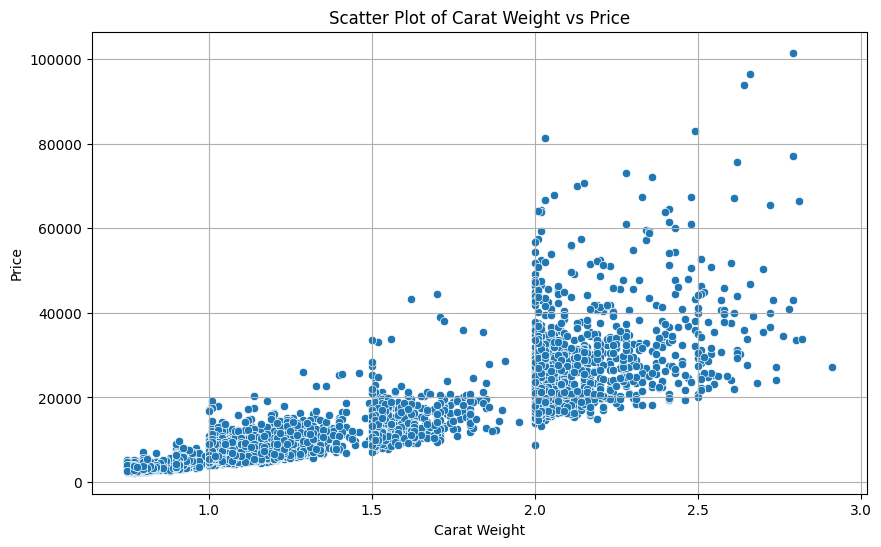

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=df, x="Carat Weight", y="Price", ax=ax) 
ax.set_title("Scatter Plot of Carat Weight vs Price")
ax.set_xlabel("Carat Weight")
ax.set_ylabel("Price")
ax.grid(True)
plt.show(); 

# Exercise 3 (5 points)

In this exercise, we will discuss design and refactoring concepts in applied data science.

Explain what the *single responsibility principle* means for a data science workflow, and why splitting a long, monolithic analysis script into small, focused functions (e.g., loading, cleaning, feature engineering, modeling) makes the code easier to test, reuse, and maintain. In your answer, also explain why refactoring should preserve the code's behavior, and how you would verify that a refactored function still produces the same results as the original.

Single responsibilty principle. Each function (or module) should do one well defined task and have one reason to change. In a analytics/data science workflow, this means separating stages such as loading data, data cleaning, modeling, and evaludation in to their own functions/modiles instead of a long script that does everything in one shoot. 

When splitting into small fucntions/modules helps:

- Testability 
- Reasuability 
- Maintainability